In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# 加载数据
df_raw = pd.read_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites.csv", 
                 index_col=0)

# 'Mut' -> 1, 'WT' -> 0, 'NoCall' -> -1
value_map = {'Mut': 1, 'WT': 0, 'NoCall': 3}
df = df_raw.map(lambda x: value_map[x])

# 检查数据
print(f"数据维度: {df.shape}")  # 显示(突变数, 细胞数)
print(df.head())  # 查看前几行

数据维度: (1810, 3154)
                     SNU601_AAACGAAAGGGAGATA  SNU601_AAACGAACACAAACGG  \
Location                                                                
chr10_100345948_T_A                        3                        3   
chr10_100979943_G_A                        3                        3   
chr10_101124154_C_T                        3                        3   
chr10_101817742_G_A                        3                        3   
chr10_102394462_A_G                        0                        3   

                     SNU601_AAACGAAGTACGCCCA  SNU601_AAACGAAGTGCAACAG  \
Location                                                                
chr10_100345948_T_A                        3                        3   
chr10_100979943_G_A                        3                        3   
chr10_101124154_C_T                        3                        3   
chr10_101817742_G_A                        3                        3   
chr10_102394462_A_G            

In [2]:
# convert sparse matrix to index, rows correspond to cells, columns correspond to mutations
def convert_sparse_matrix_to_index(df):
    df_index = pd.DataFrame(df.nonzero()).T
    df_index.columns = ['cell', 'mutation']
    return df_index

In [3]:
# 将DataFrame转换为稀疏矩阵
sparse_mtx = csr_matrix(df.values)

# 获取行列标识
mutation_ids = df.index.values
cell_ids = df.columns.values

print(f"突变ID: {mutation_ids[:5]}")  # 显示前5个突变ID
print(f"细胞ID: {cell_ids[:5]}")  # 显示前5个细胞ID

突变ID: ['chr10_100345948_T_A' 'chr10_100979943_G_A' 'chr10_101124154_C_T'
 'chr10_101817742_G_A' 'chr10_102394462_A_G']
细胞ID: ['SNU601_AAACGAAAGGGAGATA' 'SNU601_AAACGAACACAAACGG'
 'SNU601_AAACGAAGTACGCCCA' 'SNU601_AAACGAAGTGCAACAG'
 'SNU601_AAACTCGAGAAATGGG']


In [4]:
# 计算每个突变出现的细胞数
num_cells_per_mutation = np.array(sparse_mtx.getnnz(axis=1)).flatten()

# 计算每个细胞包含的突变数
num_mutations_per_cell = np.array(sparse_mtx.getnnz(axis=0)).flatten()

# 设置阈值过滤
min_cells = 10  # 突变至少在5个细胞中出现
min_mutations = 10  # 细胞至少有5个突变

# 创建过滤掩码
mut_filter = num_cells_per_mutation >= min_cells
cell_filter = num_mutations_per_cell >= min_mutations

# 应用过滤
filtered_mtx = sparse_mtx[mut_filter, :][:, cell_filter]
filtered_mutation_ids = mutation_ids[mut_filter]
filtered_cell_ids = cell_ids[cell_filter]

print(f"过滤后维度: {filtered_mtx.shape}")

index = convert_sparse_matrix_to_index(filtered_mtx)
index.to_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites_index.csv", index=False)

过滤后维度: (1810, 3154)


In [5]:
# 转置矩阵，使细胞为行(通常按细胞聚类)
cell_by_mut = filtered_mtx.toarray().T  # (细胞 × 突变)

# 然后使用标准方法计算距离和聚类
distance_matrix = pdist(cell_by_mut, metric='jaccard')


In [6]:
from scipy.cluster.hierarchy import linkage, fcluster

# 计算链接矩阵
Z = linkage(distance_matrix, method='ward')

# 确定聚类数
num_clusters = 8  # 可根据实际情况调整
clusters = fcluster(Z, t=num_clusters, criterion='maxclust')

/var/folders/yx/vkjdxytj10n2fwzdpmn014bc0000gp/T/ipykernel_57296/1862236908.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab20', n_clusters)  # 使用tab20色板，支持20种区别明显的颜色


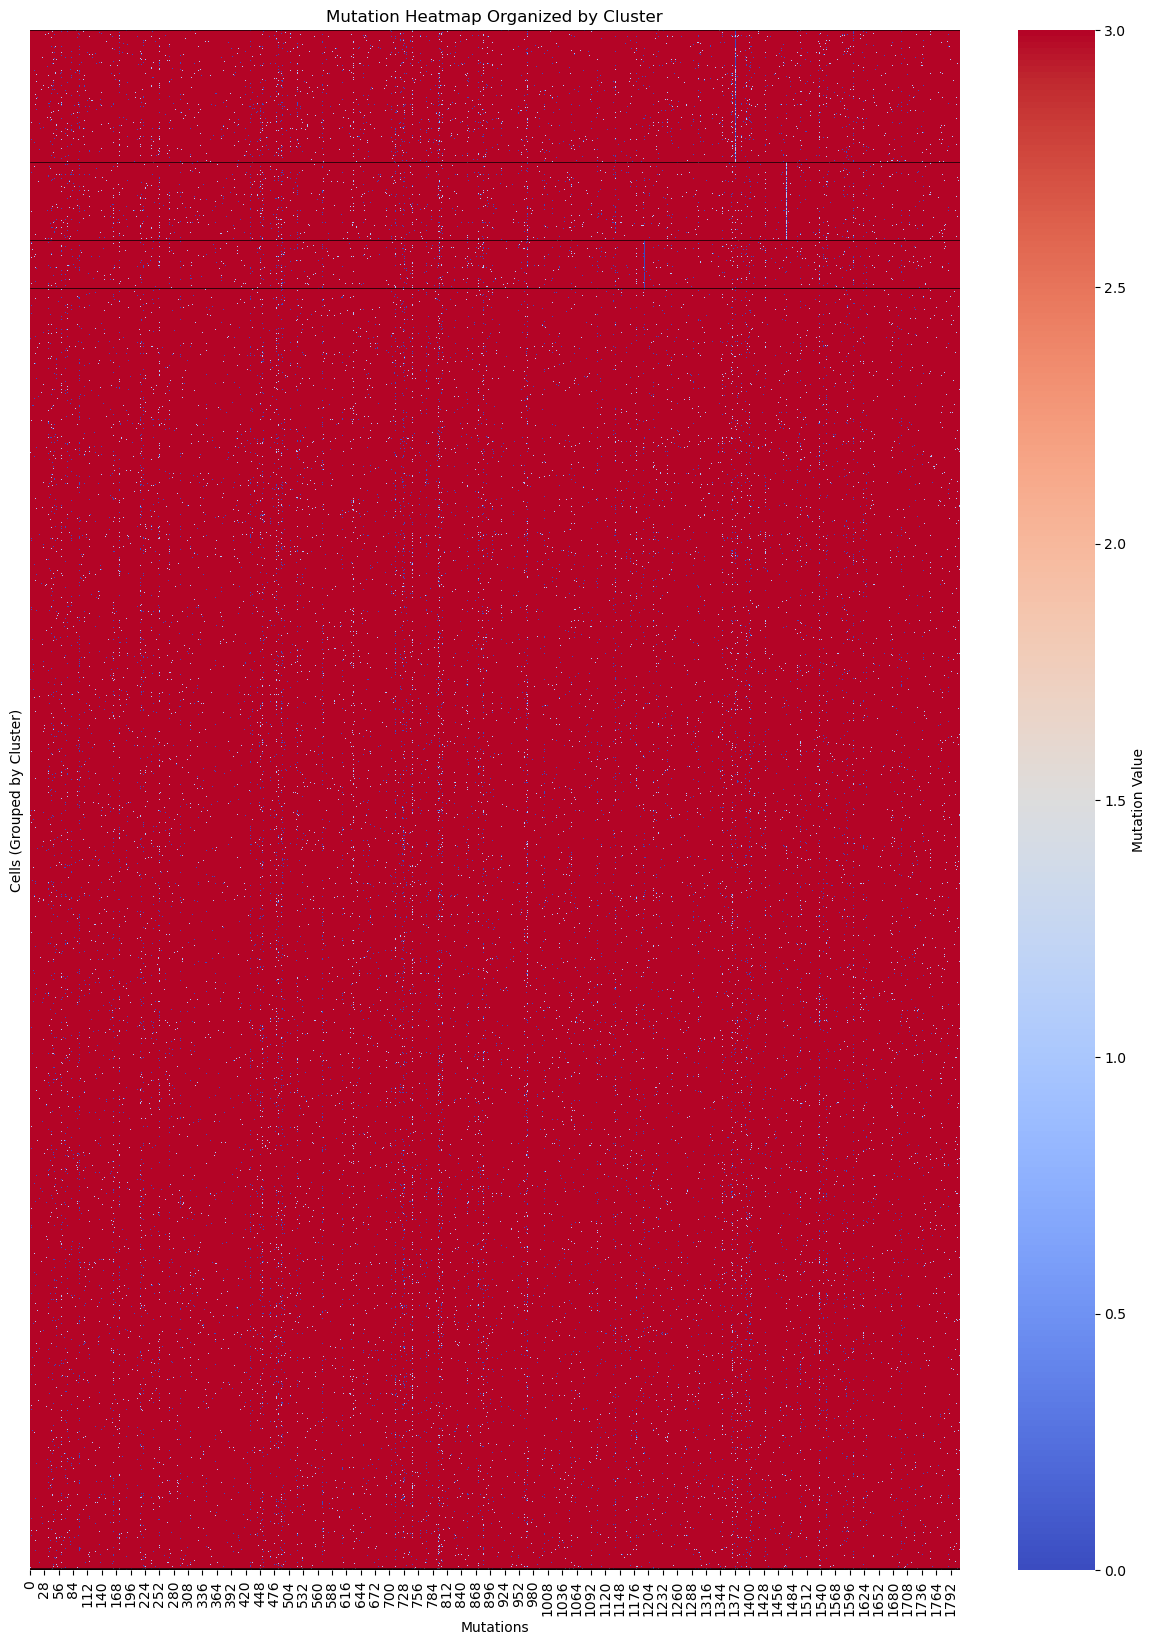

In [7]:
import matplotlib.colors as mcolors
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt
import numpy as np

# 假设 clusters 是聚类结果数组，如 [1,1,2,3,2,...]
n_clusters = len(np.unique(clusters))

# 创建颜色映射
colors = plt.cm.get_cmap('tab20', n_clusters)  # 使用tab20色板，支持20种区别明显的颜色

# 为每个cluster分配颜色
cluster_colors = {cluster: colors(i) for i, cluster in enumerate(np.unique(clusters))}
cell_colors = [cluster_colors[cluster] for cluster in clusters]


import seaborn as sns
from scipy.sparse import csr_matrix

# 按cluster排序
sorted_indices = np.argsort(clusters)
sorted_clusters = clusters[sorted_indices]
sorted_data =  filtered_mtx.T[sorted_indices]  # 假设 filtered_sparse_mtx 是原始稀疏矩阵

# 转换为稠密数组(小规模数据适用)
dense_data = sorted_data.toarray()

plt.figure(figsize=(15, 20))
sns.heatmap(
    dense_data,
    cmap='coolwarm',
    yticklabels=False,  # 不显示所有细胞ID，避免重叠
    cbar_kws={'label': 'Mutation Value'}
)

# 添加cluster分界线
prev_cluster = None
for i, cluster in enumerate(sorted_clusters):
    if cluster != prev_cluster:
        plt.axhline(i, color='black', linestyle='-', linewidth=0.5)
    prev_cluster = cluster

plt.title('Mutation Heatmap Organized by Cluster')
plt.ylabel('Cells (Grouped by Cluster)')
plt.xlabel('Mutations')
plt.show()

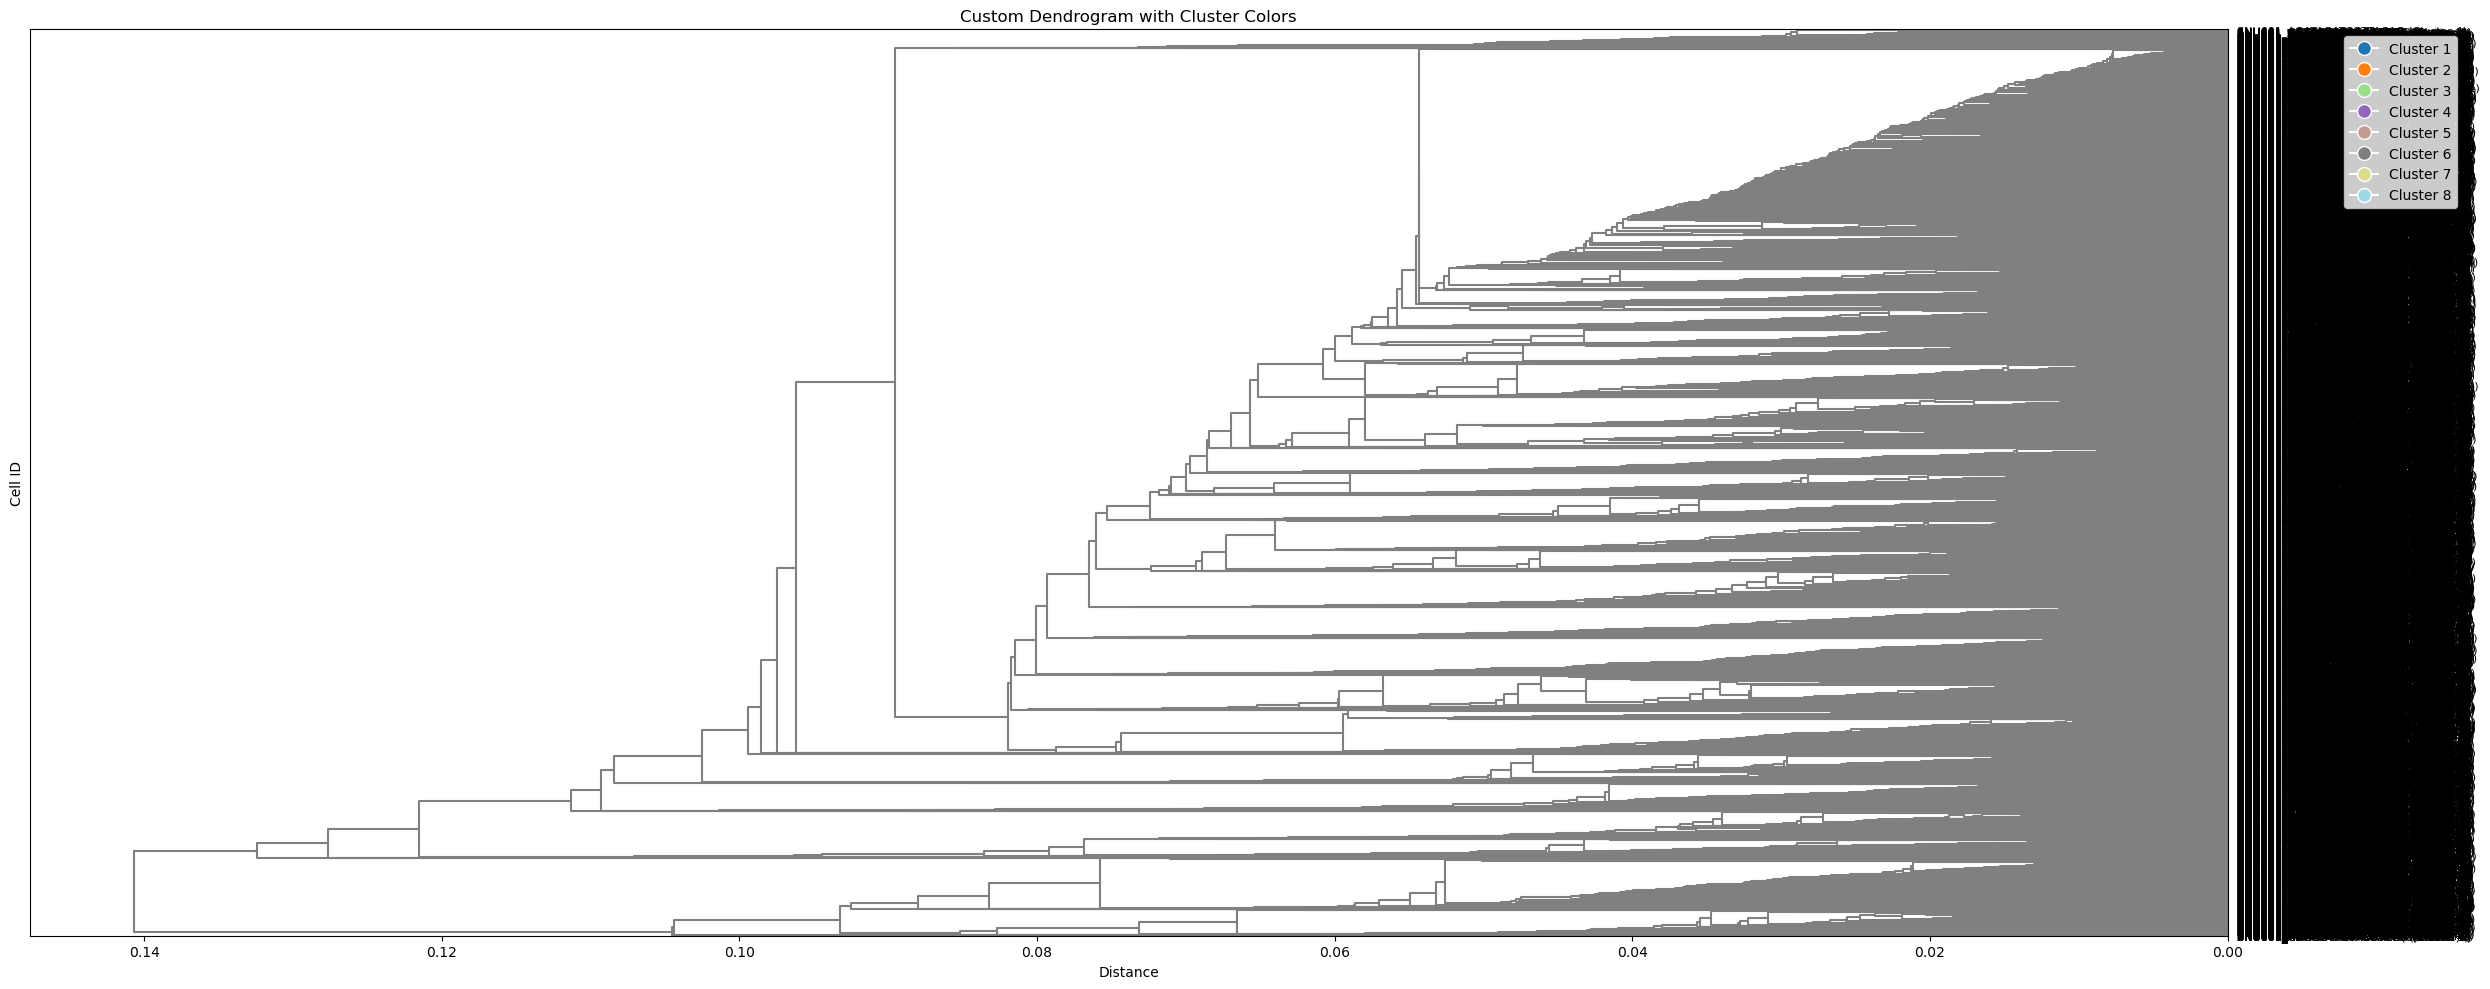

In [8]:
# 自定义树状图颜色
def color_func(*args, **kwargs):
    # 获取当前节点的索引
    node_id = kwargs['leaf']
    cluster = clusters[node_id]
    return mcolors.to_hex(cluster_colors[cluster])

plt.figure(figsize=(25, 10))
dendrogram(
    Z,
    labels=filtered_cell_ids,
    orientation='left',
    leaf_rotation=0,
    leaf_font_size=8,
    link_color_func=lambda k: 'grey',  # 连接线颜色
    leaf_label_func=lambda id: f"{cell_ids[id]} (Cluster {clusters[id]})",
    above_threshold_color='lightgray'
)

# 添加图例
patches = [plt.Line2D([0], [0], marker='o', color='w', 
                      label=f'Cluster {c}', markerfacecolor=mcolors.to_hex(color), 
                      markersize=10) for c, color in cluster_colors.items()]
plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.title('Custom Dendrogram with Cluster Colors')
plt.xlabel('Distance')
plt.ylabel('Cell ID')
plt.tight_layout()
plt.show()

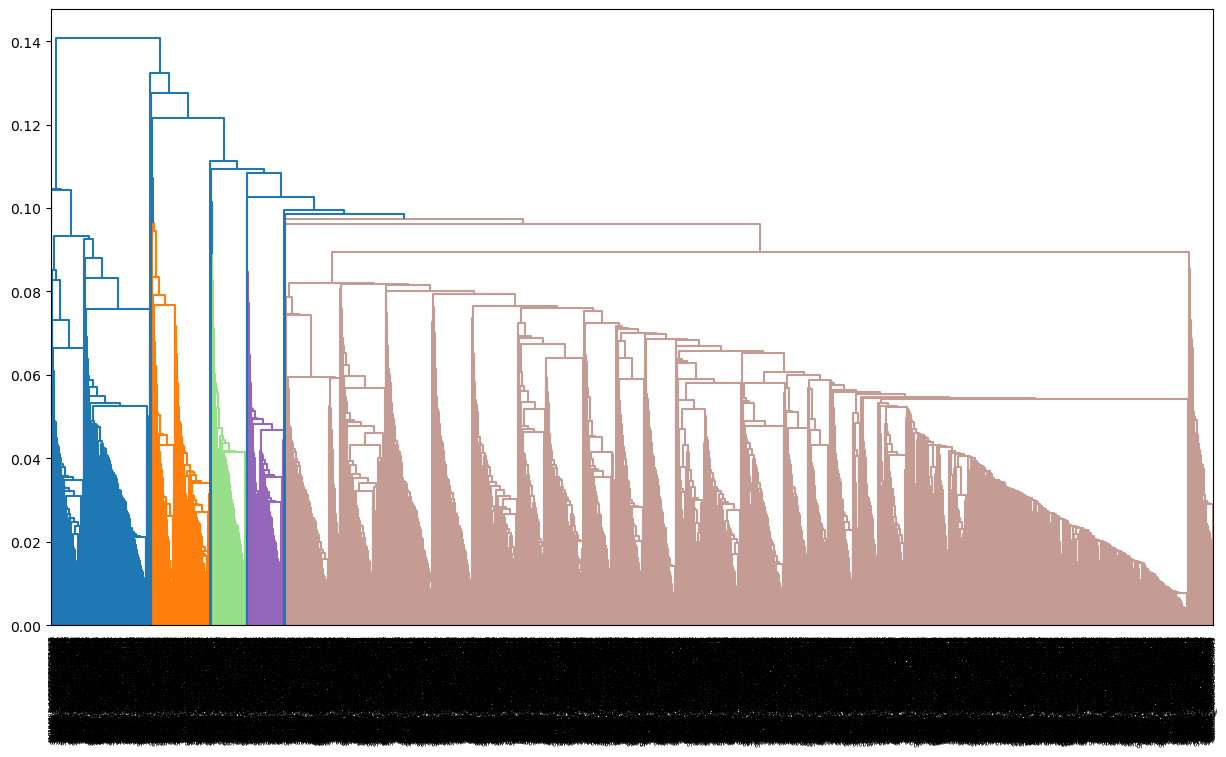

In [9]:
from scipy.cluster.hierarchy import dendrogram, set_link_color_palette

# 1. 设置颜色调色板
n_clusters = len(np.unique(clusters))
palette = plt.cm.tab20(np.linspace(0, 1, n_clusters))
set_link_color_palette([mcolors.to_hex(c) for c in palette])

# 2. 绘制树状图
plt.figure(figsize=(15, 8))
dendrogram(
    Z,
    labels=filtered_cell_ids,
    orientation='top',
    leaf_rotation=90,
    color_threshold=0.7*max(Z[:, 2])  # 设置颜色阈值
)
plt.show()

In [10]:
# 计算轮廓系数
silhouette_avg = silhouette_score(cell_by_mut, clusters, metric='jaccard')
print(f"平均轮廓系数: {silhouette_avg:.3f}")

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2008: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


平均轮廓系数: 0.077


In [11]:
# 聚类分布统计
cluster_counts = pd.Series(clusters).value_counts().sort_index()
print("各聚类包含的细胞数量:")
print(cluster_counts)

# 将聚类结果保存
result_df = pd.DataFrame({
    'Cell_ID': filtered_cell_ids,
    'Cluster': clusters
})

各聚类包含的细胞数量:
1     270
2     160
3      98
4    2622
5       1
6       1
7       1
8       1
Name: count, dtype: int64


In [12]:
# 分析每个聚类的特征突变
for cluster_id in np.unique(clusters):
    cluster_mask = (clusters == cluster_id)
    cluster_data = cell_by_mut[cluster_mask]
    
    # 计算该聚类中突变频率
    mutation_freq = cluster_data.mean(axis=0)
    
    # 找出最特异的突变（前5）
    top_indices = np.argsort(mutation_freq)[-5:][::-1]
    
    print(f"\nCluster {cluster_id} (n={sum(cluster_mask)}) 的Top突变:")
    for idx in top_indices:
        mut_id = filtered_mutation_ids[idx]
        freq = mutation_freq[idx]
        global_freq = cell_by_mut[:, idx].mean()
        enrichment = freq / global_freq if global_freq > 0 else np.inf
        print(f"{mut_id}: 频率={freq:.2f} (全局={global_freq:.2f}, 富集={enrichment:.1f}x)")


Cluster 1 (n=270) 的Top突变:
chr2_3844884_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr13_43569889_G_A: 频率=3.00 (全局=2.96, 富集=1.0x)
chr7_924197_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr21_34722688_A_G: 频率=3.00 (全局=2.99, 富集=1.0x)
chr13_46656745_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)

Cluster 2 (n=160) 的Top突变:
chrY_21193023_A_C: 频率=3.00 (全局=2.97, 富集=1.0x)
chr20_41045889_G_A: 频率=3.00 (全局=2.99, 富集=1.0x)
chr20_59068939_G_A: 频率=3.00 (全局=2.99, 富集=1.0x)
chr20_57966841_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr20_57289108_T_C: 频率=3.00 (全局=2.97, 富集=1.0x)

Cluster 3 (n=98) 的Top突变:
chr1_44823230_G_C: 频率=3.00 (全局=2.99, 富集=1.0x)
chr17_5672850_T_C: 频率=3.00 (全局=2.99, 富集=1.0x)
chr17_45250674_T_A: 频率=3.00 (全局=2.99, 富集=1.0x)
chr4_54076685_C_G: 频率=3.00 (全局=2.99, 富集=1.0x)
chr17_4531957_C_T: 频率=3.00 (全局=2.98, 富集=1.0x)

Cluster 4 (n=2622) 的Top突变:
chr14_68695084_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr9_21119183_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr12_108826873_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr7_76202667_C_T: 频率=3.00 (全局=2.99, 富集=1.0x)
chr12_1287